In [1]:
from utils import load_counties, SOC2_MAP, set_plot_style
import pandas as pd
import numpy as np
import sqlite3

import seaborn as sns
import matplotlib.pyplot as plt

import geopandas as gpd
from shapely.geometry import Point

In [2]:
counties = load_counties()

In [3]:
con = sqlite3.connect("../data_raw/NEW_MAIN.db")
cur = con.cursor()

cur.execute("SELECT name FROM sqlite_master WHERE type='table';")
tables = cur.fetchall()
print(tables)

person_onet      = pd.read_sql_query("SELECT * FROM person_onet;", con)
experience_onet  = pd.read_sql_query("SELECT * FROM experience_onet;", con)
education        = pd.read_sql_query("SELECT * FROM education;", con)

con.close()

[('person',), ('education',), ('experience',), ('certification',), ('sqlite_sequence',), ('region',), ('country',), ('interest',), ('joblevel',), ('skill',), ('degree',), ('df_degree',), ('df_degree_2',), ('major',), ('minor',), ('AIExposure',), ('jobzone',), ('person_onet',), ('certification_ai',), ('certification_tech',), ('location',), ('experience_onet',), ('certification_ai_tech',)]


In [4]:
# Matching experience with job categories (job zones + ONET) and education

experience=pd.read_csv('../data_raw/Job_matching_results_1020.csv')

experience_onet=experience_onet[['EXPERIENCE_ID', 'COMPANY_ID', 'COMPANY_NAME',  'COMPANY_LOCATION_GEO', 'START_DATE', 'END_DATE']]
experience=experience[['PERSON_ID', 'EXPERIENCE_ID', 'EXP_JOB_TITLE', 'Job Zone_final', 'Code_final', 'LATEST_JOB_TITLE', 'LATEST_JOB_ONET_CODE', 'EDUCATION_ID', 'EDU_MAJOR']]

experience['EXPERIENCE_ID'] = (pd.to_numeric(experience['EXPERIENCE_ID'], errors='coerce')
                               .astype('Int64').astype(str).replace('<NA>', None))
experience['EDUCATION_ID'] = (pd.to_numeric(experience['EDUCATION_ID'], errors='coerce')
                               .astype('Int64').astype(str).replace('<NA>', None))
experience_onet['EXPERIENCE_ID'] = (pd.to_numeric(experience_onet['EXPERIENCE_ID'], errors='coerce')
                               .astype('Int64').astype(str).replace('<NA>', None))
education['EDUCATION_ID'] = (pd.to_numeric(education['EDUCATION_ID'], errors='coerce')
                               .astype('Int64').astype(str).replace('<NA>', None))

experience=experience.merge(experience_onet, on='EXPERIENCE_ID', how='left')

experience['PERSON_ID']=experience['PERSON_ID'].astype(str)
education['PERSON_ID']=education['PERSON_ID'].astype(str)

education=education.sort_values(['PERSON_ID', 'START_DATE'])
education_first=education.groupby('PERSON_ID').first().reset_index()
education_first=education_first[['PERSON_ID', 'START_DATE']]

experience=experience.merge(education_first, on='PERSON_ID', how='left', suffixes=('_EXPERIENCE', '_SCHOOL'))
experience=experience.merge(person_onet[['PERSON_ID', 'SEX']], on='PERSON_ID', how='left')

| Job Zone                         | Preparation Needed                                         | Typical Examples                                            |
| -------------------------------- | ---------------------------------------------------------- | ----------------------------------------------------------- |
| **1 — Little or no preparation** | May require short-term on-the-job training                 | dishwashers, hand packers                                   |
| **2 — Some preparation**         | Usually HS diploma + some training                         | retail sales, receptionist, basic machine operators         |
| **3 — Medium preparation**       | Vocational school / associate degree / moderate experience | electricians, dental assistants, graphic designers          |
| **4 — Considerable preparation** | Bachelor’s degree + several years of experience            | accountants, teachers, analysts, most non-exec office roles |
| **5 — Extensive preparation**    | Graduate/professional degree + substantial experience      | physicians, engineers, lawyers, professors, scientists      |


In [5]:
# By soc2 (job industries)

experience["soc2"] = experience["Code_final"].astype(str).str.slice(0,2)

soc2_map = SOC2_MAP

experience["soc_broad"] = experience["soc2"].map(soc2_map)
experience['next_soc_broad']=experience.groupby('PERSON_ID')['soc_broad'].shift(-1)

In [6]:
# Matching experience with seniority levels

experience_seniority=pd.read_csv('../data_raw/Trajectory_Seniority_1027.csv')
experience_seniority=experience_seniority.dropna(subset='EXPERIENCE_ID')

experience_seniority['EXPERIENCE_ID']=experience_seniority['EXPERIENCE_ID'].astype(int)
experience_seniority['EXPERIENCE_ID']=experience_seniority['EXPERIENCE_ID'].astype(str)

experience=experience.merge(experience_seniority[['EXPERIENCE_ID', 'seniority_label', 'seniority level']], on='EXPERIENCE_ID', how='left')
experience=experience.rename(columns={'seniority level':'seniority_level'})

# seniority mapping
def map_seniority(level):
    if pd.isna(level):
        return np.nan
    elif level in [1, 2]:
        return "Early-career"
    elif level in [3, 4]:
        return "Mid-career"
    elif level in [5, 6, 7]:
        return "Senior leadership"
    else:
        return np.nan

experience["seniority_group"] = experience["seniority_level"].map(map_seniority)
experience['next_seniority_group'] = experience.groupby('PERSON_ID')['seniority_group'].shift(-1)

| Seniority Level          | Description                                                                 | Typical Examples                                                                                  |
|--------------------------|-----------------------------------------------------------------------------|---------------------------------------------------------------------------------------------------|
| **1 — Entry Level**      | Roles requiring minimal experience; often internships or trainee positions  | Accounting Intern; Software Engineer Trainee; Paralegal                                           |
| **2 — Junior Level**     | Early-career roles with limited experience and basic responsibilities       | Accounts Receivable Bookkeeper; Junior Software QA Engineer; Legal Adviser                        |
| **3 — Associate Level**  | Fully trained professionals; often senior individual contributors           | Senior Tax Accountant; Lead Electrical Engineer; Attorney                                         |
| **4 — Manager Level**    | Roles overseeing teams, projects, or operational units                     | Account Manager; Superintendent Engineer; Lead Lawyer                                             |
| **5 — Director Level**   | Department- or division-level leadership; strategic and supervisory duties  | Chief of Accountants; VP Network Engineering; Head of Legal                                       |
| **6 — Executive Level**  | Organization-wide leadership roles below C-suite                           | Managing Director (Treasury); Director of Engineering, Backend Systems; Attorney (Partner)        |
| **7 — Senior Executive** | Highest-level leadership and corporate officers                            | CFO; COO; CEO                                                                                      |


In [7]:
# Inferring age (not really used further)
# assuming the first educational year is around persons 18-teen birthday

experience['START_DATE_EXPERIENCE'] = pd.to_datetime(experience["START_DATE_EXPERIENCE"], errors="coerce")
experience['START_DATE_SCHOOL']     = pd.to_datetime(experience["START_DATE_SCHOOL"], errors="coerce")

# compute difference in years
diff_years = (experience['START_DATE_EXPERIENCE'] - experience['START_DATE_SCHOOL']).dt.days / 365.25
experience['age'] = 18 + diff_years

# age brackets
bins  = [0, 24, 34, 44, 54, 64, 74, 200]
labels = [
    "18–24",
    "25–34",
    "35–44",
    "45–54",
    "55–64",
    "65–74",
    "75+"
]

experience['age_bracket'] = pd.cut(
    experience['age'],
    bins=bins,
    labels=labels,
    right=True,       # 24 goes into "18–24"
    include_lowest=True
)

# larger age bins
bins = [0, 24, 34, 44, 54, 120]
labels = ["18–24", "25–34", "35–44", "45–54", "55+"]

experience["age_cat"] = pd.cut(experience["age"], bins=bins, labels=labels, right=True)
experience["age_cat"] = experience["age_bracket"].replace({ "55–64":"55+",
                                                            "65–74":"55+",
                                                            "75+":"55+" })

experience["age_cat"] = pd.Categorical(experience["age_cat"], categories=labels, ordered=True)
experience["age_cat"]= experience["age_cat"].astype("str")

In [8]:
# Matching  experience with counties

experience['geometry'] = experience['COMPANY_LOCATION_GEO'].apply(
    lambda geo: Point(float(geo.split(',')[1]), float(geo.split(',')[0])) if isinstance(geo, str) and ',' in geo else None
)

experience = gpd.GeoDataFrame(
    experience,
    geometry='geometry',
    crs='EPSG:4326'
)

counties = counties.to_crs(epsg=4326)
experience = experience.sjoin(
    counties[['STATEFP', 'COUNTYFP', 'NAME', 'geometry']],
    how='left',
    predicate='intersects'
)

In [9]:
# Creating columns necessary for further analysis

experience['END_DATE'] = pd.to_datetime(experience['END_DATE'], errors='coerce')

experience = experience.sort_values(['PERSON_ID', 'START_DATE_EXPERIENCE'])

experience['next_start_date'] = experience.groupby('PERSON_ID')['START_DATE_EXPERIENCE'].shift(-1)
experience['next_state'] = experience.groupby('PERSON_ID')['STATEFP'].shift(-1)
experience['next_county'] = experience.groupby('PERSON_ID')['COUNTYFP'].shift(-1)
experience['next_name'] = experience.groupby('PERSON_ID')['NAME'].shift(-1)

experience["STCOFIPS"] = experience["STATEFP"].astype(str).str.zfill(2)  + experience["COUNTYFP"].astype(str).str.zfill(3)
experience["STCOFIPS_next"] = experience["next_state"].astype(str).str.zfill(2)+ experience["next_county"].astype(str).str.zfill(3)

experience['next_job_zone'] = experience.groupby('PERSON_ID')['Job Zone_final'].shift(-1)

In [10]:
experience.shape

(1078325, 38)

In [11]:
experience["geometry_wkt"] = experience.geometry.apply(lambda g: g.wkt)
experience = experience.drop(columns="geometry")

experience.to_parquet("../data_generated/experience.parquet", index=False)

## Visual Explorations

In [12]:
set_plot_style()

In [13]:
experience.PERSON_ID.nunique()

447466

/tmp/ipykernel_3822/1088058827.py:171: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax4.set_xticklabels(ax4.get_xticklabels(), rotation=90)


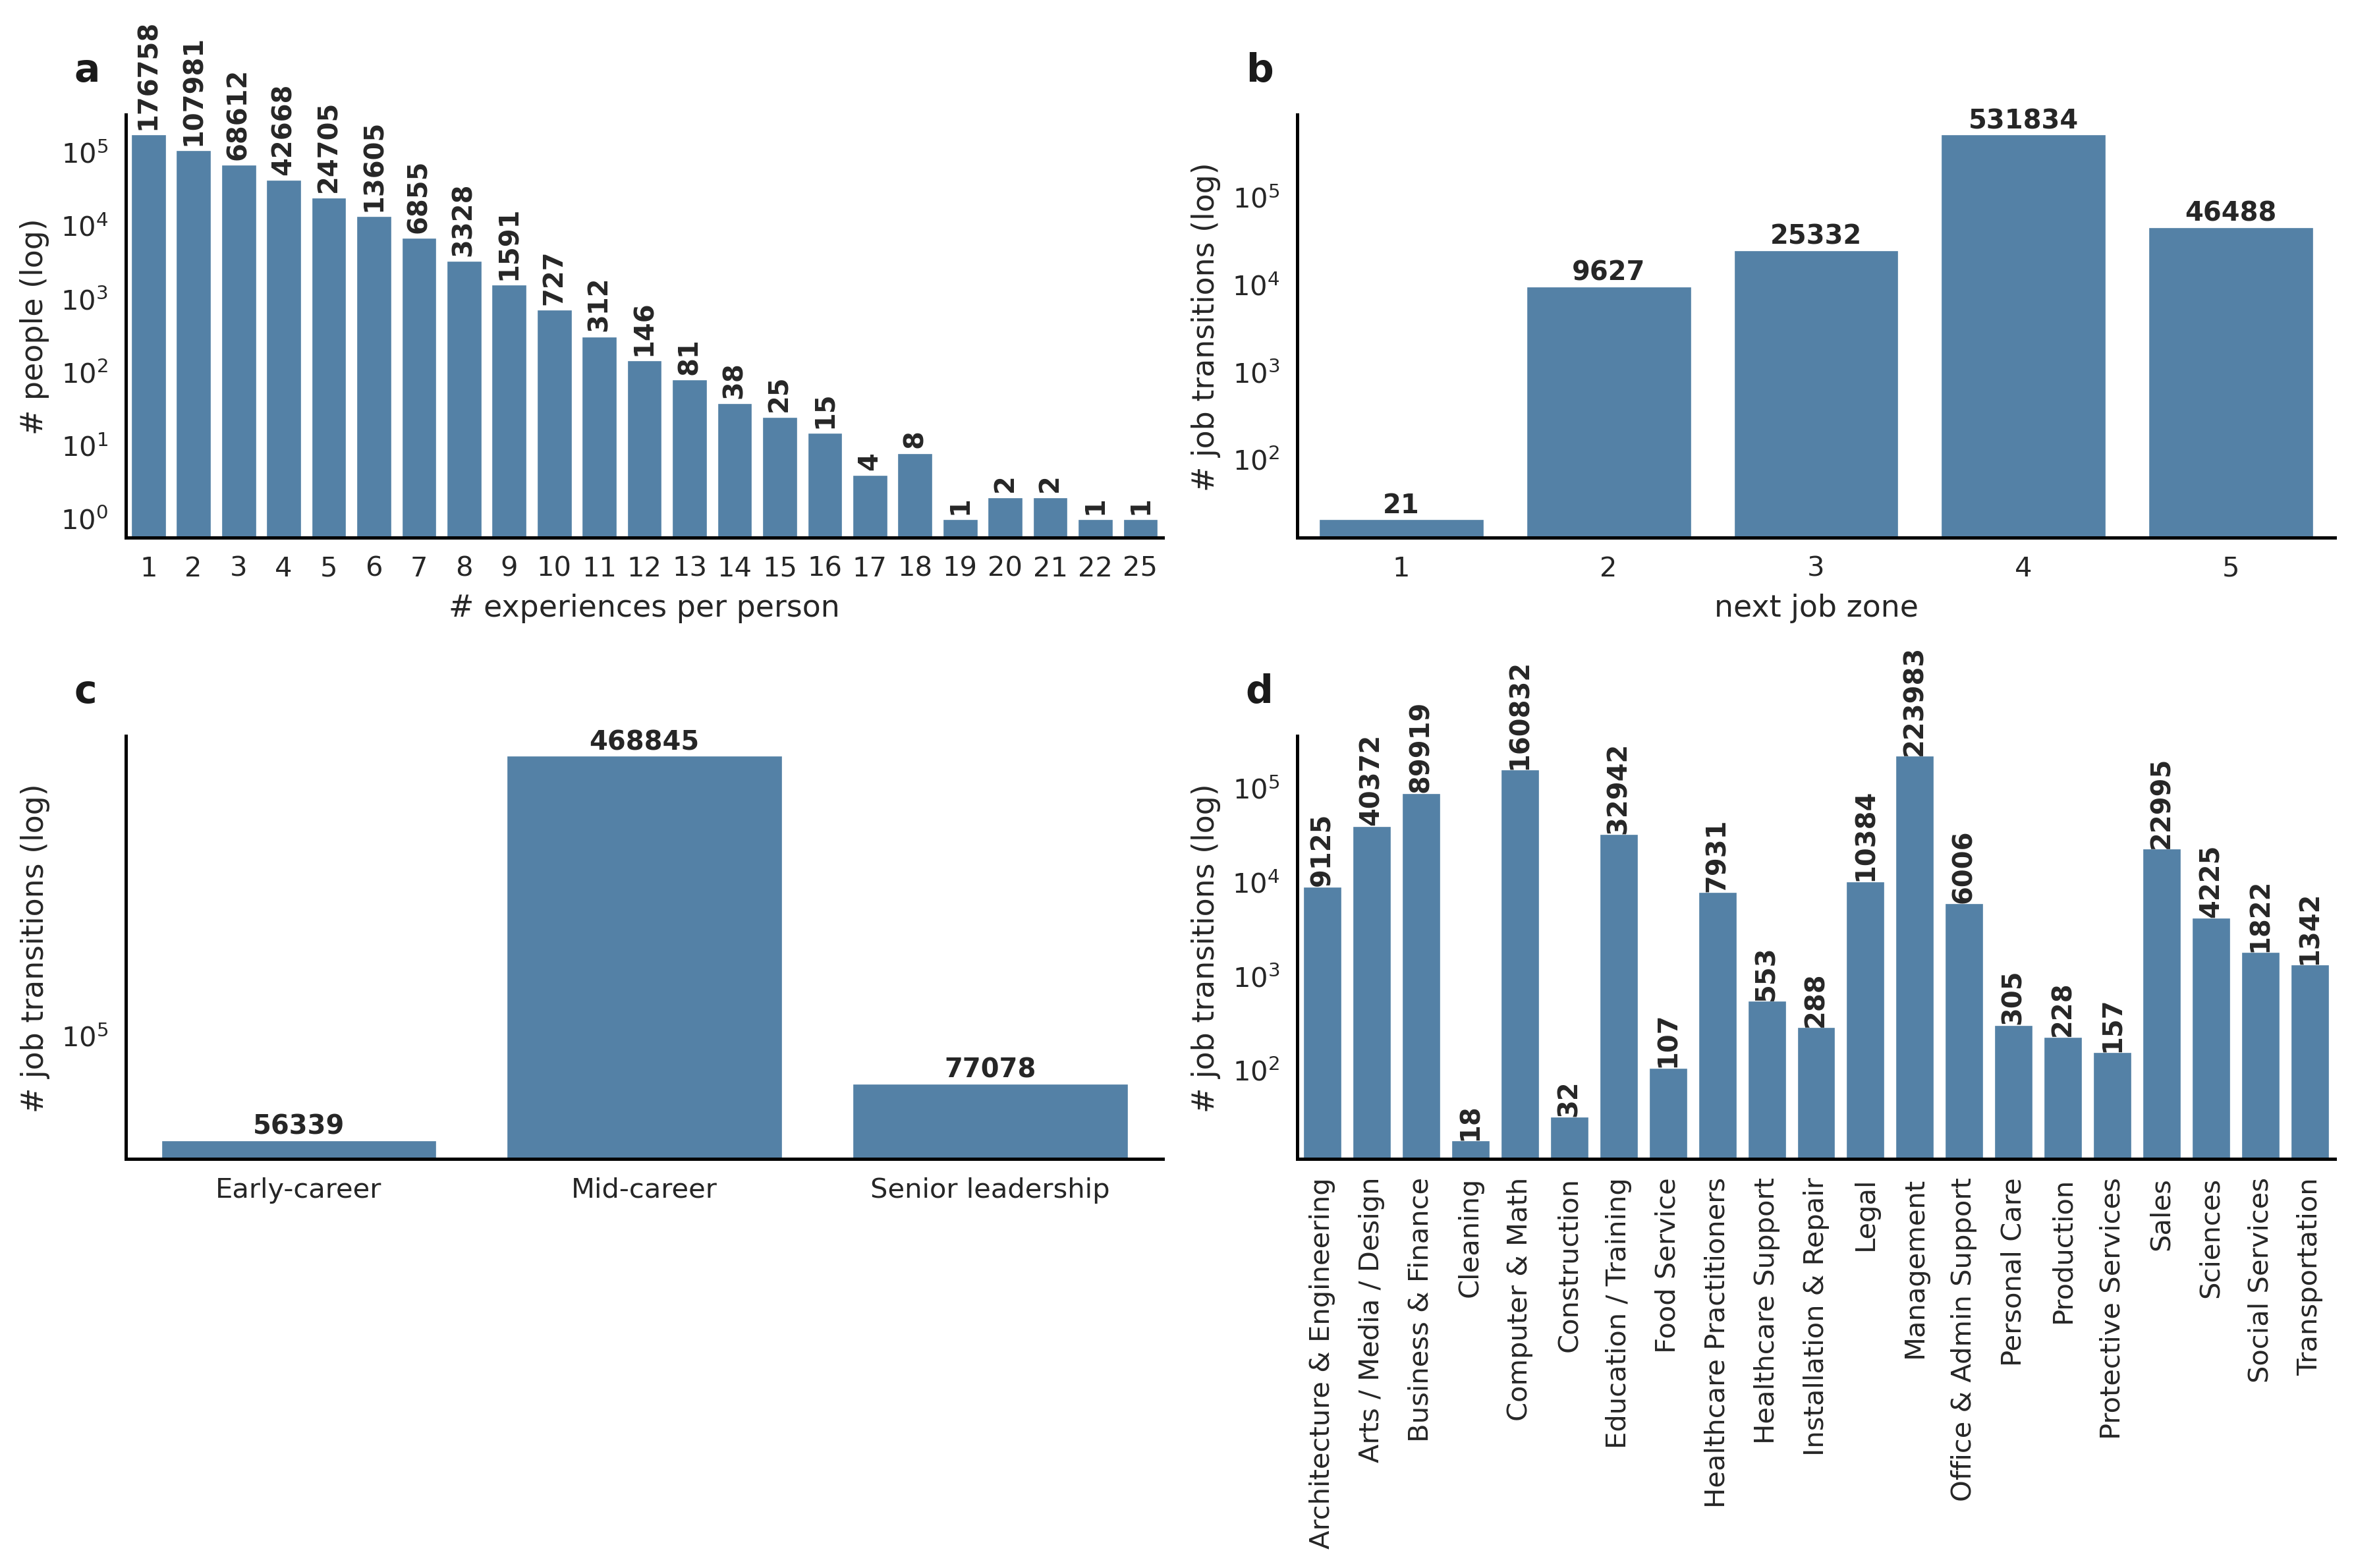

In [14]:
### ON EXPERIENCE

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
(ax1, ax2), (ax3, ax4) = axes

# ============================================================
# 1. Experiences per person
# ============================================================

exp_counts = (
    experience.groupby('PERSON_ID')['EXPERIENCE_ID']
    .count()
    .reset_index()
    .EXPERIENCE_ID
    .value_counts()
    .sort_index()
    .reset_index()
)
exp_counts.columns = ['n_experiences', 'n_people']

sns.barplot(
    data=exp_counts,
    x='n_experiences',
    y='n_people',
    color='steelblue',
    ax=ax1
)

# labels
for i, row in exp_counts.iterrows():
    if row['n_experiences'] >= 0:
        ax1.text(
            x=i,
            y=row['n_people'] * 1.15,
            s=f"{int(row['n_people'])}",
            ha='center',
            va='bottom',
            fontweight='bold',
            rotation=90
        
        )

ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.set_yscale("log")
ax1.set_xlabel("# experiences per person")
ax1.set_ylabel("# people (log)")


# ============================================================
# 2. Next job zone
# ============================================================

zone_counts_z = (
    experience['next_job_zone']
    .value_counts()
    .reset_index()
    .rename(columns={'count': 'n_people'})
)

zone_counts_z['next_job_zone'] = zone_counts_z['next_job_zone'].astype(int)
zone_counts_z = zone_counts_z.sort_values('next_job_zone').reset_index(drop=True)

sns.barplot(
    data=zone_counts_z,
    x='next_job_zone',
    y='n_people',
    color='steelblue',
    ax=ax2
)

for i, row in zone_counts_z.iterrows():
    ax2.text(
        x=i,
        y=row['n_people'],
        s=f"{int(row['n_people'])}",
        ha='center',
        va='bottom',
        fontweight='bold'
    )

ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.set_yscale("log")
ax2.set_xlabel("next job zone")
ax2.set_ylabel("# job transitions (log)")


# ============================================================
# 3. Next seniority group
# ============================================================

order = ["Early-career", "Mid-career", "Senior leadership"]

zone_counts_s = (
    experience['next_seniority_group']
    .value_counts()
    .reset_index()
    .rename(columns={'count': 'n_people', 'next_seniority_group': 'next_seniority_group'})
)

zone_counts_s['next_seniority_group'] = pd.Categorical(
    zone_counts_s['next_seniority_group'],
    categories=order,
    ordered=True
)
zone_counts_s = zone_counts_s.sort_values('next_seniority_group').reset_index(drop=True)

sns.barplot(
    data=zone_counts_s,
    x='next_seniority_group',
    y='n_people',
    color='steelblue',
    ax=ax3
)

for i, row in zone_counts_s.iterrows():
    ax3.text(
        x=i,
        y=row['n_people'],
        s=f"{int(row['n_people'])}",
        ha='center',
        va='bottom',
        fontweight='bold'
    )

ax3.spines["top"].set_visible(False)
ax3.spines["right"].set_visible(False)
ax3.set_yscale("log")
ax3.set_xlabel("")
ax3.set_ylabel("# job transitions (log)")


# ============================================================
# 4. Next SOC broad category
# ============================================================

zone_counts_i = (
    experience['next_soc_broad']
    .value_counts()
    .reset_index()
    .rename(columns={'count': 'n_people', 'next_soc_broad': 'next_soc_broad'})
)

zone_counts_i = zone_counts_i.sort_values('next_soc_broad').reset_index(drop=True)

sns.barplot(
    data=zone_counts_i,
    x='next_soc_broad',
    y='n_people',
    color='steelblue',
    ax=ax4
)

for i, row in zone_counts_i.iterrows():
    ax4.text(
        x=i,
        y=row['n_people'],
        s=f"{int(row['n_people'])}",
        ha='center',
        va='bottom',
        fontweight='bold',
        rotation=90
    )

ax4.spines["top"].set_visible(False)
ax4.spines["right"].set_visible(False)
ax4.set_yscale("log")
ax4.set_xlabel("")
ax4.set_ylabel("# job transitions (log)")
ax4.set_xticklabels(ax4.get_xticklabels(), rotation=90)

# ============================================================

plots_l = ['a', 'b', 'c', 'd']
for ia, ax in enumerate(fig.axes): 
    x,y = -0.05,1.06
    ax.text(x,y,  plots_l[ia],
        color = 'k',#'lightgreen',
        horizontalalignment='left',
        verticalalignment='bottom',
        weight = 'bold',
        transform=ax.transAxes,fontsize = 14)
    
plt.tight_layout()

plt.savefig('../fig/si/si_panel1.pdf', bbox_inches='tight')

plt.show()
